[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch61_LabCh61_Ship_And_Watch.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 61: Shipping and Watching a Model** (Part XIII: Small, Fast and Shipped).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=61](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=61)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch61 - Ship a model, then watch it
## Package it, time it, and find out which kinds of trouble your monitors can see

This lab goes with **Chapter 61** of *The Why Book of Deep Learning, Part 2*.

Every lab so far stopped at a test accuracy. This one starts there. You train a small clothing classifier, and
then you do the two jobs that come after training: you **ship** it (package it so that another program can call
it, and find out how long one answer takes) and you **watch** it (simulate sixty days of production in which the
world changes, and find out which changes you would have noticed without a single label).

| Part | Question | Steps |
|---|---|---|
| One: package | What goes in the file, and does the reloaded model give the same answers? | 2 to 8 |
| Two: serve | How do you call it safely, and how long does one request take? | 9 to 12 |
| Three: watch | The inputs drift and labels come late. Which monitors fire, and when? | 13 to 20 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Put the preprocessing inside the model, and show what happens when it is done twice or not at all | Steps 3 and 5 |
| Save a whole model, reload it and prove the predictions are identical | Step 6 |
| Export an inference-only artefact and call it without Keras | Steps 7 and 8 |
| Write a prediction function that refuses bad input instead of answering it | Step 9 |
| Measure latency as a median and a 95th percentile, per request and per image | Steps 10 to 12 |
| Build four monitors that need no labels, and calibrate their alert thresholds | Steps 14 and 15 |
| Say which kinds of drift those monitors catch early, catch late, or cannot see at all | Steps 17 to 20 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **This lab runs on a CPU, and says so.** The saved copy was run on the author's laptop CPU with no GPU.
> Every timing is a measurement on the machine that ran it. **Your numbers will differ**, from machine to
> machine and from run to run. Read the ratios and the order of magnitude and ignore the last digits.

> **Runtime:** about three minutes on a laptop CPU.

> **Honest scale:** this is a miniature. The model has about 31 thousand parameters, "production" is a loop in
> this notebook, a "day" is 500 images drawn from the test set, and the drift is something we apply ourselves,
> so we always know the true accuracy. A real service has a network, a queue, many machines and no answer key.
> The method carries over. The numbers do not.

> **Files:** everything this lab saves goes into a temporary folder made in Step 1. Nothing is written next
> to the notebook.

---
## Step 1 - Imports, one seed, and a temporary folder

In [1]:
import os, time, tempfile, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 61
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()

WORK = tempfile.mkdtemp(prefix="labch61_")          # every saved file goes here
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs visible:", len(tf.config.list_physical_devices("GPU")), "| CPU cores reported:", os.cpu_count())
print("temporary folder:", WORK)

TensorFlow 2.21.0 | Keras 3.14.1


GPUs visible: 0 | CPU cores reported: 12
temporary folder: <python>


---
## Step 2 - The data, and one class kept back for later

Fashion-MNIST has ten kinds of clothing. Imagine a second-hand shop that photographs each item and wants it
filed automatically. When the model is trained the shop sells **nine** kinds of item. It does not sell bags
yet. So we train on nine classes and keep every **Bag** image aside. In Step 19 the shop starts selling bags.

- `x_fit`: 45,000 images used for training.
- `x_val`: 9,000 images held out. They choose nothing during training, and later they are the **reference
  window** that production is compared with.
- `x_test`: 9,000 images that play the part of production traffic.
- `x_bag`: 1,000 images of the class the model has never seen.

The images stay as **raw bytes**, `uint8` from 0 to 255, exactly as a camera would deliver them.

> **Predict:** the model will have nine outputs. When it is shown a bag, what can it answer?

In [2]:
ALL_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
BAG = 8
NAMES = [n for i, n in enumerate(ALL_NAMES) if i != BAG]             # the nine classes the model knows
remap = -np.ones(10, dtype="int64"); remap[[i for i in range(10) if i != BAG]] = np.arange(9)

(x_tr, y_tr), (x_te, y_te) = keras.datasets.fashion_mnist.load_data()
known = y_tr != BAG
x_known, y_known = x_tr[known], remap[y_tr[known]]
order = rng.permutation(len(x_known))
x_known, y_known = x_known[order], y_known[order]
x_val, y_val = x_known[:9000], y_known[:9000]
x_fit, y_fit = x_known[9000:], y_known[9000:]
x_test, y_test = x_te[y_te != BAG], remap[y_te[y_te != BAG]]
x_bag = x_te[y_te == BAG]

for name, a in [("x_fit", x_fit), ("x_val", x_val), ("x_test", x_test), ("x_bag", x_bag)]:
    print(f"{name:7s} {str(a.shape):16s} {a.dtype}  min {a.min()}  max {a.max()}")
print("classes the model will know:", NAMES)

x_fit   (45000, 28, 28)  uint8  min 0  max 255
x_val   (9000, 28, 28)   uint8  min 0  max 255
x_test  (9000, 28, 28)   uint8  min 0  max 255
x_bag   (1000, 28, 28)   uint8  min 0  max 255
classes the model will know: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Ankle boot']


---
## Step 3 - The model, with its preprocessing inside

The network wants numbers between 0 and 1 in the shape `(28, 28, 1)`. The camera delivers bytes in the shape
`(28, 28)`. Somebody has to convert one into the other, **every time the model is called, for ever**. We make
that somebody the model: its first two layers are `Rescaling(1/255)` and `Reshape`. The input the model
declares is the raw image.

The counting rules are Chapter 14's: a convolution has `(k * k * channels_in + 1) * filters` parameters and a
Dense layer has `(inputs + 1) * units`. `Rescaling`, `Reshape`, pooling and `Flatten` have none.

> **Predict:** how many parameters do the two preprocessing layers add? And which layer holds the most?

In [3]:
def build_model():
    raw = keras.Input(shape=(28, 28), dtype="uint8", name="raw_image")
    x = layers.Rescaling(1.0 / 255, name="scale_0_1")(raw)          # preprocessing lives in the model
    x = layers.Reshape((28, 28, 1), name="add_channel")(x)
    x = layers.Conv2D(16, 3, activation="relu", name="conv1")(x)
    x = layers.MaxPooling2D(name="pool1")(x)
    x = layers.Conv2D(32, 3, activation="relu", name="conv2")(x)
    x = layers.MaxPooling2D(name="pool2")(x)
    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(32, activation="relu", name="embedding")(x)
    out = layers.Dense(9, activation="softmax", name="probabilities")(x)
    return keras.Model(raw, out, name="clothing_v1")

model = build_model()
model.summary()

by_hand = (3 * 3 * 1 + 1) * 16 + (3 * 3 * 16 + 1) * 32 + (5 * 5 * 32 + 1) * 32 + (32 + 1) * 9
print("by hand: 160 + 4,640 + 25,632 + 297 =", f"{by_hand:,}")
assert model.count_params() == by_hand == 30729

Model: "clothing_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ raw_image (InputLayer)          │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scale_0_1 (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_channel (Reshape)           │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Dense)               │ (None, 32)             │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Dense)           │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,729 (120.04 KB)

 Trainable params: 30,729 (120.04 KB)

 Non-trainable params: 0 (0.00 B)

by hand: 160 + 4,640 + 25,632 + 297 = 30,729


---
## Step 4 - Train it

Four passes over 45,000 images. This is the part every earlier lab was about, so we do not linger.

> **Predict:** Fashion-MNIST with nine classes and a network this small. Will the test accuracy be nearer
> 75%, 87% or 97%?

In [4]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
history = model.fit(x_fit, y_fit, epochs=4, batch_size=64, validation_data=(x_val, y_val), verbose=2)
print("training took %.0f s" % (time.time() - t0))

p_val = model.predict(x_val, batch_size=500, verbose=0)
p_test = model.predict(x_test, batch_size=500, verbose=0)
VAL_ACC = float((p_val.argmax(1) == y_val).mean())
TEST_ACC = float((p_test.argmax(1) == y_test).mean())
print("validation accuracy: %.1f%%   test accuracy: %.1f%%" % (100 * VAL_ACC, 100 * TEST_ACC))
recall = [(p_test.argmax(1)[y_test == c] == c).mean() for c in range(9)]
print("accuracy on each class (a slice of the test set):")
for c in np.argsort(recall):
    print(f"   {NAMES[c]:12s} {100 * recall[c]:5.1f}%")

Epoch 1/4


704/704 - 6s - 8ms/step - accuracy: 0.7726 - loss: 0.6189 - val_accuracy: 0.8332 - val_loss: 0.4562


Epoch 2/4


704/704 - 5s - 7ms/step - accuracy: 0.8483 - loss: 0.4163 - val_accuracy: 0.8508 - val_loss: 0.3960


Epoch 3/4


704/704 - 5s - 7ms/step - accuracy: 0.8639 - loss: 0.3701 - val_accuracy: 0.8591 - val_loss: 0.3698


Epoch 4/4


704/704 - 5s - 7ms/step - accuracy: 0.8746 - loss: 0.3414 - val_accuracy: 0.8668 - val_loss: 0.3554


training took 20 s


validation accuracy: 86.7%   test accuracy: 86.8%
accuracy on each class (a slice of the test set):
   Shirt         64.1%
   Pullover      74.7%
   Dress         82.5%
   Coat          87.1%
   T-shirt/top   88.4%
   Sneaker       93.9%
   Ankle boot    95.7%
   Sandal        97.1%
   Trouser       97.4%


### Why we see this

One number for the whole test set hides a wide spread. Shoes and trousers are nearly always right. Shirts,
which look like T-shirts, pullovers and coats at 28 by 28 pixels, are wrong far more often. Keep that spread in
mind: in Step 19 the mix of classes changes, and the average moves although the model has not changed at all.

---
## Step 5 - Training-serving skew: the same weights, fed the wrong way

Suppose the preprocessing were **not** in the model. The training script divides by 255 on its own, and the
team that writes the service has to do the same thing again, by hand, in another file, perhaps in another
language. To see what a mismatch costs we build `bare`: the same trained layers without the two preprocessing
layers. Then we feed it the test set prepared four ways.

> **Predict:** which of the three wrong ways will raise an error? What accuracy will each give?

In [5]:
bare_in = keras.Input(shape=(28, 28, 1), name="already_prepared")
h = bare_in
for layer in model.layers[3:]:                      # reuse the trained layers after scale and reshape
    h = layer(h)
bare = keras.Model(bare_in, h, name="bare")

f = x_test.astype("float32")[..., None]
ways = [
    ("divide by 255, as in training", f / 255.0),
    ("forgot to scale: 0 to 255", f),
    ("another convention: -1 to 1", f / 127.5 - 1.0),
    ("scaled twice: divide by 255, twice", f / 255.0 / 255.0),
]
SKEW = {}
for label, data in ways:
    p = bare.predict(data, batch_size=500, verbose=0)
    acc = float((p.argmax(1) == y_test).mean())
    SKEW[label] = acc
    print(f"{label:36s} accuracy {100 * acc:5.1f}%   mean confidence {100 * p.max(1).mean():5.1f}%")
print("errors raised: 0")

divide by 255, as in training        accuracy  86.8%   mean confidence  86.6%


forgot to scale: 0 to 255            accuracy  82.3%   mean confidence  99.9%


another convention: -1 to 1          accuracy  79.0%   mean confidence  90.3%


scaled twice: divide by 255, twice   accuracy  16.4%   mean confidence  20.6%
errors raised: 0


### Why we see this

Nothing fails loudly. Every version takes an array of the right shape and returns nine probabilities that add
up to one. Only the accuracy tells them apart, and in production you do not have the accuracy. The sizes of
the damage differ widely. One mistake wrecks the model, and somebody will notice. Another costs a few points,
and that one can live in a service for months. Look at the confidence column too: fed pixels 255 times too
large, the model is surer of itself than it has ever been. This is **training-serving skew**, and the cure is
structural: with the preprocessing inside the model there is no second copy to get wrong.

---
## Step 6 - Save the whole model, reload it, and prove the answers are identical

`model.save("x.keras")` writes one file holding the architecture, the weights and the optimiser's state, so
that training could be resumed. `model.save_weights` writes the variables without the architecture: you need
the code that builds the model before you can load them.

"It reloaded without an error" is not a test. The test is: **the same inputs give the same outputs**.

> **Predict:** the model has 30,729 parameters, about 120 KB as float32. Adam keeps two extra numbers for
> every parameter. Roughly how big will the `.keras` file be? And will the reloaded predictions match exactly
> or only closely?

In [6]:
keras_path = os.path.join(WORK, "clothing_v1.keras")
weights_path = os.path.join(WORK, "clothing_v1.weights.h5")
model.save(keras_path)
model.save_weights(weights_path)

reloaded = keras.models.load_model(keras_path)
p_again = reloaded.predict(x_test, batch_size=500, verbose=0)
MAX_DIFF_KERAS = float(np.abs(p_again - p_test).max())
print("largest difference in any probability, original against reloaded: %g" % MAX_DIFF_KERAS)
print("same predicted class on all %d test images: %s" % (len(x_test), bool((p_again.argmax(1) == p_test.argmax(1)).all())))
assert MAX_DIFF_KERAS < 1e-6

kb = lambda path: os.path.getsize(path) / 1024
n_opt = int(sum(np.prod(v.shape) for v in model.optimizer.variables))
print("the model's parameters: %s numbers = %.0f KB as float32" % (f"{model.count_params():,}", model.count_params() * 4 / 1024))
print("Adam's state          : %s numbers (two per parameter, plus a step counter and a learning rate)" % f"{n_opt:,}")
assert n_opt == 2 * model.count_params() + 2
print("weights file (.weights.h5): %.0f KB" % kb(weights_path))
print("whole model (.keras)      : %.0f KB   (a zip: configuration + weights + optimiser state)" % kb(keras_path))
print("the reloaded model still has its optimiser:", type(reloaded.optimizer).__name__)

largest difference in any probability, original against reloaded: 0
same predicted class on all 9000 test images: True
the model's parameters: 30,729 numbers = 120 KB as float32
Adam's state          : 61,460 numbers (two per parameter, plus a step counter and a learning rate)
weights file (.weights.h5): 397 KB
whole model (.keras)      : 405 KB   (a zip: configuration + weights + optimiser state)
the reloaded model still has its optimiser: Adam


---
## Step 7 - Export an inference-only artefact, and call it without Keras

A service does not train. It needs the forward pass and nothing else. `model.export(folder)` writes a
TensorFlow **SavedModel**: the computation as a fixed graph plus the weights, with one entry point called
`serve`. It carries no Python class, no optimiser and no `fit`.

We load it back with `tf.saved_model.load`, which does not use Keras at all, and call `serve` on raw bytes.

Two details matter in real code:

- **Keep the loaded object.** Write `artefact = tf.saved_model.load(...)` and then `artefact.serve(...)`. If
  you keep only the function (`serve = tf.saved_model.load(...).serve`), the object that owns the weights is
  thrown away and the first call fails with an error about deleted variables.
- The entry point has a **signature**: one tensor of shape `(None, 28, 28)` and type `uint8`.

> **Predict:** what happens if you hand `serve` the same images as `float32`?

In [7]:
export_dir = os.path.join(WORK, "clothing_v1_export")
model.export(export_dir, verbose=0)

def folder_kb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1024

print("what is in the folder:", sorted(os.listdir(export_dir)))
print("size of the export: %.0f KB" % folder_kb(export_dir))

artefact = tf.saved_model.load(export_dir)          # keep this object alive
print("entry points:", list(artefact.signatures.keys()))
print("serve expects:", artefact.serve.concrete_functions[0].structured_input_signature[0][0])

p_export = np.concatenate([artefact.serve(tf.constant(x_test[i:i + 500])).numpy() for i in range(0, len(x_test), 500)])
MAX_DIFF_EXPORT = float(np.abs(p_export - p_test).max())
print("largest difference, Keras model against exported artefact: %g" % MAX_DIFF_EXPORT)
assert MAX_DIFF_EXPORT < 1e-5 and (p_export.argmax(1) == p_test.argmax(1)).all()
print("has a fit method:", hasattr(artefact, "fit"), "| has an optimiser:", hasattr(artefact, "optimizer"))

try:
    artefact.serve(tf.constant(x_test[:2].astype("float32")))
    print("float32 input: accepted")
except Exception as e:
    print("float32 input: refused ->", type(e).__name__ + ":", str(e).split(". Received")[0][:150])

INFO:tensorflow:Assets written to: <python>


INFO:tensorflow:Assets written to: <python>


what is in the folder: ['assets', 'fingerprint.pb', 'saved_model.pb', 'variables']
size of the export: 302 KB
entry points: ['serve', 'serving_default']
serve expects: TensorSpec(shape=(None, 28, 28), dtype=tf.uint8, name='raw_image')


largest difference, Keras model against exported artefact: 0
has a fit method: False | has an optimiser: False
float32 input: refused -> TypeError: Binding inputs to tf.function failed due to `Can not cast TensorSpec(shape=(2, 28, 28), dtype=tf.float32, name='raw_image') to TensorSpec(shape=(None,


### Why we see this

The export gives the same answers because it is the same arithmetic with the training machinery removed. The
refusal of `float32` is a feature. The signature is a contract, and a client that sends the wrong type is
stopped at the door instead of being answered wrongly, as the skewed inputs of Step 5 were.

One oddity, since we promised to report what really happens: the export is not small. In the Keras version
that ran the saved copy of this lab, the export's variables file holds every weight twice, under two names
(`tf.train.list_variables(export_dir + "/variables/variables")` lists them). Inference-only means "no
training machinery". It does not have to mean "smallest file". The next step writes a file that is.

---
## Step 8 - Optional: an on-device file

Phones and small boards do not run a SavedModel. They run a compact single file read by a small interpreter.
TensorFlow's format for this was called TensorFlow Lite until 2024 and is now called **LiteRT**. Keras can
write it with `model.export(path, format="litert")`.

This step is wrapped in `try`: the converter is the part of this lab most likely to differ between
installations. If it fails on your machine, read the message and move on. Nothing later depends on it.

> **Predict:** the file holds the same float32 weights and no optimiser. How big will it be?

In [8]:
try:
    lite_path = os.path.join(WORK, "clothing_v1.tflite")
    model.export(lite_path, format="litert", verbose=0)
    interp = tf.lite.Interpreter(model_path=lite_path)
    interp.allocate_tensors()
    inp, outp = interp.get_input_details()[0], interp.get_output_details()[0]
    print("on-device file: %.0f KB | input %s %s" % (kb(lite_path), inp["shape"], inp["dtype"].__name__))
    lite = []
    for img in x_test[:300]:                        # one image at a time, as a phone would
        interp.set_tensor(inp["index"], img[None])
        interp.invoke()
        lite.append(interp.get_tensor(outp["index"])[0])
    lite = np.array(lite)
    print("largest difference from the Keras model on 300 images: %g" % np.abs(lite - p_test[:300]).max())
    print("same predicted class on all 300:", bool((lite.argmax(1) == p_test[:300].argmax(1)).all()))
except Exception as e:
    print("The on-device export did not work in this installation:", type(e).__name__, str(e)[:200])

INFO:tensorflow:Assets written to: <python>


INFO:tensorflow:Assets written to: <python>


Saved artifact at '<python>'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28), dtype=tf.uint8, name='raw_image')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  1907210862864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1908212116816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1908212116240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1908212116624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1908212115856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1908212117584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1908212117776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1908212118352: TensorSpec(shape=(), dtype=tf.resource, name=None)


Saved artifact at '<python>'.


on-device file: 126 KB | input [ 1 28 28] uint8
largest difference from the Keras model on 300 images: 1.2815e-06
same predicted class on all 300: True


---
## Step 9 - A prediction function that can say no

The model answers anything of the right shape. A service must not. `predict_request` is the small piece of
code that stands between the outside world and the model. It checks the request, calls the artefact and turns
the nine numbers into something a caller can use: a name, a confidence, the model's version, and a flag when
the model is unsure.

The rules it enforces are all things that go wrong in practice: the wrong shape, a batch that is too large,
pixels already scaled to 0 to 1 (which would be scaled a second time, as in Step 5), values that are not
numbers, and a blank image.

> **Predict:** five bad requests follow the good one. Which of them would the bare model have answered?

In [9]:
MODEL_VERSION = "clothing_v1"
MAX_BATCH = 64
REVIEW_BELOW = 0.60            # under this confidence the answer is marked for a person to check

def validate(images):
    a = np.asarray(images)
    if a.ndim == 2:
        a = a[None]
    if a.ndim != 3 or a.shape[1:] != (28, 28):
        raise ValueError(f"expected images of shape (n, 28, 28), got {a.shape}")
    if len(a) == 0 or len(a) > MAX_BATCH:
        raise ValueError(f"between 1 and {MAX_BATCH} images per request, got {len(a)}")
    if a.dtype != np.uint8:
        if not np.issubdtype(a.dtype, np.number):
            raise ValueError(f"pixels must be numbers, got {a.dtype}")
        if not np.isfinite(a).all():
            raise ValueError("pixels contain NaN or infinity")
        if a.min() < 0 or a.max() > 255:
            raise ValueError(f"pixels must lie in 0 to 255, got {a.min():g} to {a.max():g}")
        if a.max() <= 1.0 and a.max() > 0:
            raise ValueError("pixels look already scaled to 0 to 1: send raw 0 to 255, the model scales them")
        if not np.equal(a, np.round(a)).all():
            raise ValueError("pixels must be whole numbers from 0 to 255")
        a = a.astype("uint8")
    if (a.reshape(len(a), -1).max(1) == a.reshape(len(a), -1).min(1)).any():
        raise ValueError("at least one image is blank (every pixel the same)")
    return a

def predict_request(images):
    a = validate(images)
    probs = artefact.serve(tf.constant(a)).numpy()
    top = probs.argmax(1)
    return [{"label": NAMES[k], "confidence": round(float(p[k]), 3), "needs_review": bool(p[k] < REVIEW_BELOW),
             "model": MODEL_VERSION} for k, p in zip(top, probs)]

print("a good request:", predict_request(x_test[0]))
bad = [
    ("a 32 x 32 image", np.zeros((1, 32, 32), "uint8")),
    ("100 images at once", x_test[:100]),
    ("already divided by 255", x_test[:2] / 255.0),
    ("a NaN pixel", np.where(np.arange(784).reshape(1, 28, 28) == 5, np.nan, x_test[:1].astype("float32"))),
    ("a blank image", np.zeros((1, 28, 28), "uint8")),
]
for what, req in bad:
    try:
        predict_request(req)
        print(f"{what:24s} -> answered")
    except ValueError as e:
        print(f"{what:24s} -> refused: {e}")

blank = model.predict(np.zeros((1, 28, 28), "uint8"), verbose=0)[0]
print("without the check, the model calls a blank image '%s' with confidence %.0f%%" % (NAMES[blank.argmax()], 100 * blank.max()))
share_review = float((p_test.max(1) < REVIEW_BELOW).mean())
acc_review = float((p_test.argmax(1) == y_test)[p_test.max(1) < REVIEW_BELOW].mean())
acc_rest = float((p_test.argmax(1) == y_test)[p_test.max(1) >= REVIEW_BELOW].mean())
print("on the test set %.1f%% of answers are marked for review; accuracy there %.1f%%, on the rest %.1f%%" % (
      100 * share_review, 100 * acc_review, 100 * acc_rest))

a good request: [{'label': 'Ankle boot', 'confidence': 0.953, 'needs_review': False, 'model': 'clothing_v1'}]
a 32 x 32 image          -> refused: expected images of shape (n, 28, 28), got (1, 32, 32)
100 images at once       -> refused: between 1 and 64 images per request, got 100
already divided by 255   -> refused: pixels look already scaled to 0 to 1: send raw 0 to 255, the model scales them
a NaN pixel              -> refused: pixels contain NaN or infinity
a blank image            -> refused: at least one image is blank (every pixel the same)


without the check, the model calls a blank image 'T-shirt/top' with confidence 21%
on the test set 11.7% of answers are marked for review; accuracy there 53.2%, on the rest 91.2%


---
## Step 10 - How long does one answer take? Three ways to call the same model

A user sends **one** image and waits. So we time requests of batch size 1, one after another, and we report
two numbers: the **median** (half the requests were faster) and the **95th percentile**, written p95 (one
request in twenty was slower than this).

The same weights can be called three ways:

1. `model.predict(x)`: the method every lab has used. It is built for large arrays: it sets up a data
   pipeline and a progress loop on every call.
2. `model(x, training=False)`: the model called directly as a function.
3. `artefact.serve(x)`: the exported graph.

The timer follows Chapter 59's rules: warm up first, time many requests, never the first one.

> **Predict:** rank the three from slowest to fastest at batch size 1. By what factor do the extremes differ:
> 2, 10 or 100?

In [10]:
def time_requests(fn, batch, n_requests, warmup=15):
    """Send n_requests requests of `batch` images. Returns each request's time in milliseconds."""
    for i in range(warmup):
        fn(x_test[i * batch:(i + 1) * batch])
    times = np.empty(n_requests)
    for i in range(n_requests):
        lo = (i * batch) % (len(x_test) - batch)
        req = x_test[lo:lo + batch]
        t0 = time.perf_counter()
        fn(req)
        times[i] = time.perf_counter() - t0
    return times * 1000

def describe(ms):
    return dict(median=float(np.median(ms)), p95=float(np.percentile(ms, 95)), p99=float(np.percentile(ms, 99)),
                mean=float(ms.mean()), worst=float(ms.max()))

callers = {
    "model.predict(x)": (lambda x: model.predict(x, verbose=0), 60),
    "model(x, training=False)": (lambda x: model(x, training=False).numpy(), 300),
    "artefact.serve(x)": (lambda x: artefact.serve(tf.constant(x)).numpy(), 1000),
}
WAYS = {}
print("one image per request, on this machine's CPU")
print(f"{'':26s} {'median':>9s} {'p95':>9s}")
for name, (fn, n) in callers.items():
    WAYS[name] = describe(time_requests(fn, 1, n))
    print(f"{name:26s} {WAYS[name]['median']:7.2f} ms {WAYS[name]['p95']:7.2f} ms")
print("predict is %.0f times slower than the exported function (medians)" % (
      WAYS["model.predict(x)"]["median"] / WAYS["artefact.serve(x)"]["median"]))

# the cold start: load the artefact from disk and answer the very first request
t0 = time.perf_counter(); fresh = tf.saved_model.load(export_dir); t_load = (time.perf_counter() - t0) * 1000
t0 = time.perf_counter(); fresh.serve(tf.constant(x_test[:1])); t_first = (time.perf_counter() - t0) * 1000
print("cold start: load %.0f ms + first request %.1f ms, against a warm median of %.2f ms" % (
      t_load, t_first, WAYS["artefact.serve(x)"]["median"]))

one image per request, on this machine's CPU
                              median       p95


model.predict(x)            180.42 ms  288.13 ms


model(x, training=False)     20.85 ms   32.32 ms


artefact.serve(x)             2.35 ms    6.62 ms
predict is 77 times slower than the exported function (medians)


cold start: load 144 ms + first request 78.4 ms, against a warm median of 2.35 ms


### Why we see this

The three calls do the same arithmetic on the same weights. The difference is everything around the
arithmetic. `predict` prepares for a large dataset each time it is called, and for one image that
preparation is nearly the whole cost. The exported function is a fixed graph with nothing to prepare. For a
model this small the framework's overhead is far larger than the model, which is the usual state of affairs
for small models and single requests. The first request after loading is slow for Chapter 59's reason: the
first call builds and allocates.

---
## Step 11 - Latency against batch size, 1 to 64

Now send requests of 1, 2, 4, ... 64 images to the exported function, 400 requests at each size.

Two columns to compare: the time for the **request** (what the caller waits) and the time **per image**
(what the machine spends, and so what you pay).

> **Predict:** a request of 64 images does 64 times the arithmetic of a request of 1. Will it take 64 times
> as long, about 10 times, or less than 3 times?

batch     median        p95    per image   images/s


    1     2.59 ms     5.78 ms    2589.4 us        386


    2     2.69 ms     7.76 ms    1343.6 us        744


    4     3.02 ms     7.79 ms     755.1 us      1,324


    8     3.22 ms    10.67 ms     403.0 us      2,482


   16     3.13 ms     8.24 ms     195.9 us      5,104


   32     3.56 ms     8.44 ms     111.2 us      8,995


   64     4.53 ms    10.57 ms      70.8 us     14,134
request time, batch 64 against batch 1: 1.7 times
cost per image, batch 1 against batch 64: 37 times


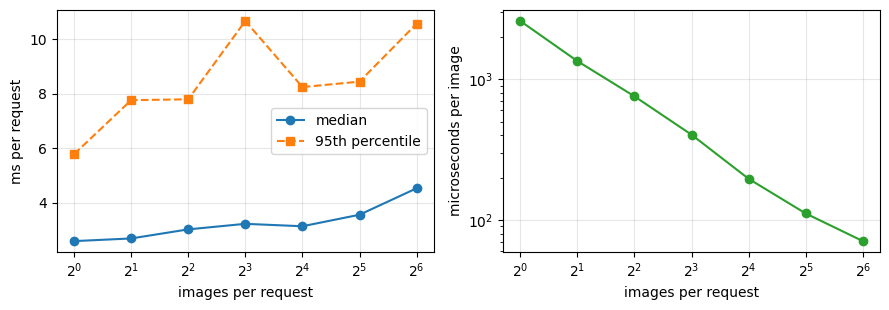

In [11]:
serve_fn = lambda x: artefact.serve(tf.constant(x)).numpy()
SWEEP = {}
print(f"{'batch':>5s} {'median':>10s} {'p95':>10s} {'per image':>12s} {'images/s':>10s}")
for b in [1, 2, 4, 8, 16, 32, 64]:
    SWEEP[b] = describe(time_requests(serve_fn, b, 400))
    d = SWEEP[b]
    print(f"{b:5d} {d['median']:8.2f} ms {d['p95']:8.2f} ms {1000 * d['median'] / b:9.1f} us {1000 * b / d['median']:10,.0f}")
print("request time, batch 64 against batch 1: %.1f times" % (SWEEP[64]["median"] / SWEEP[1]["median"]))
print("cost per image, batch 1 against batch 64: %.0f times" % (64 * SWEEP[1]["median"] / SWEEP[64]["median"]))

plt.figure(figsize=(9, 3.2))
bs = list(SWEEP)
plt.subplot(1, 2, 1)
plt.plot(bs, [SWEEP[b]["median"] for b in bs], "o-", label="median")
plt.plot(bs, [SWEEP[b]["p95"] for b in bs], "s--", label="95th percentile")
plt.xscale("log", base=2); plt.xlabel("images per request"); plt.ylabel("ms per request"); plt.legend(); plt.grid(alpha=0.3)
plt.subplot(1, 2, 2)
plt.plot(bs, [1000 * SWEEP[b]["median"] / b for b in bs], "o-", color="tab:green")
plt.xscale("log", base=2); plt.yscale("log"); plt.xlabel("images per request"); plt.ylabel("microseconds per image"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Why we see this

Each request pays a fixed cost (entering the graph, starting every operation, copying the answer out) and a
cost per image. At batch 1 the fixed cost is almost everything, so a request sixty-four times larger takes
only a little longer. That is Chapter 59's throughput curve seen from the other side, and it is the reason
servers collect requests that arrive close together into one batch (**dynamic batching**). The price is
paid by the first request in the batch, which waits for the others.

A benchmark at batch 64 says almost nothing about a service that will be called with batch 1. Measure the
shape of traffic you will really serve.

---
## Step 12 - Why the average is the wrong number

Take 3,000 single-image requests and look at the whole distribution, not one summary of it.

> **Predict:** which is larger, the mean or the median? How many times the median is the slowest request?

median      2.13 ms   =    1.0 x the median
mean        2.42 ms   =    1.1 x the median
p95         4.35 ms   =    2.0 x the median
p99         7.46 ms   =    3.5 x the median
worst      21.42 ms   =   10.1 x the median
share of requests slower than the mean: 34%
share of requests slower than twice the median: 5.5%


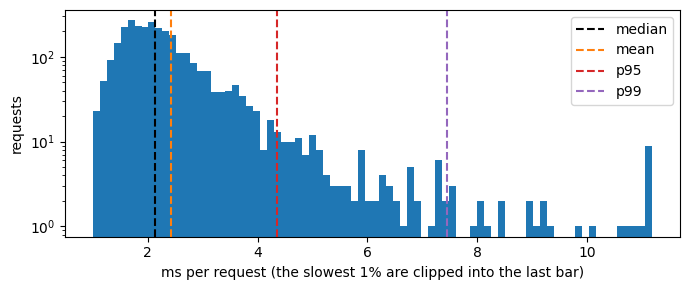

In [12]:
ms = time_requests(serve_fn, 1, 3000)
TAIL = describe(ms)
for k in ["median", "mean", "p95", "p99", "worst"]:
    print(f"{k:7s} {TAIL[k]:8.2f} ms   = {TAIL[k] / TAIL['median']:6.1f} x the median")
print("share of requests slower than the mean: %.0f%%" % (100 * (ms > ms.mean()).mean()))
print("share of requests slower than twice the median: %.1f%%" % (100 * (ms > 2 * TAIL["median"]).mean()))

plt.figure(figsize=(7, 3))
plt.hist(np.clip(ms, 0, TAIL["p99"] * 1.5), bins=80, color="tab:blue")
for k, c in [("median", "k"), ("mean", "tab:orange"), ("p95", "tab:red"), ("p99", "tab:purple")]:
    plt.axvline(TAIL[k], color=c, ls="--", label=k)
plt.yscale("log"); plt.xlabel("ms per request (the slowest 1% are clipped into the last bar)"); plt.ylabel("requests"); plt.legend()
plt.tight_layout(); plt.show()

### Why we see this

Latency has a floor and no ceiling. A request cannot be much faster than the arithmetic allows, but it can be
much slower: the operating system gives the processor to something else, memory is tidied, another program
wakes up. So the distribution has a long tail to the right. The mean is pulled by a few slow requests and
describes none of them. The median describes the typical request and hides the tail. The **95th and 99th
percentiles** describe what your unluckiest users feel, and a user who makes twenty requests will probably
meet the 95th percentile once.

The tail you see here comes from one laptop doing other things. On a real service add queues, the network and
other tenants, and the tail gets longer, not shorter.

---
# Part Three: watching

## Step 13 - Ways the world can change

The model is now frozen. The world is not. We need tools to change the traffic on purpose:

- `rotate(x, degrees)`: the camera, or the way items are laid down, is tilted.
- `blur(x, sigma)`: a lens out of focus or a cheaper camera.
- `dim(x, gain)`: darker lighting.

All three take and return raw `uint8` images. Two more changes need no image tool: a different **mix of
classes**, and a change in the **rule** that says which label is right.

> **Predict:** which of the three image changes leaves the average brightness of an image almost untouched?

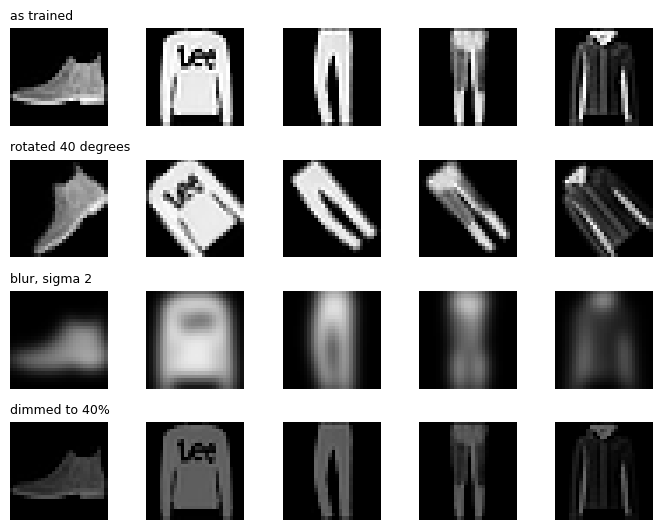

at full strength      accuracy  mean confidence  mean brightness


as trained               86.8%            86.6%             71.3


rotated 40 degrees       27.6%            70.0%             69.8


blur, sigma 2            66.0%            56.1%             70.1


dimmed to 40%            84.1%            70.9%             28.5


In [13]:
def rotate(x, degrees):
    if degrees == 0:
        return x
    a = np.deg2rad(degrees); c, s = np.cos(a), np.sin(a); mid = 13.5
    t = np.array([c, -s, mid - c * mid + s * mid, s, c, mid - s * mid - c * mid, 0, 0], "float32")
    out = keras.ops.image.affine_transform(x[..., None].astype("float32"), np.tile(t, (len(x), 1)), interpolation="bilinear")
    return np.clip(np.round(np.array(out)[..., 0]), 0, 255).astype("uint8")

def blur(x, sigma):
    if sigma <= 0:
        return x
    r = int(np.ceil(3 * sigma)); k = np.exp(-0.5 * (np.arange(-r, r + 1) / sigma) ** 2); k /= k.sum()
    f = np.pad(x.astype("float32"), ((0, 0), (r, r), (r, r)), mode="edge")
    f = sum(k[i] * f[:, i:i + 28, :] for i in range(2 * r + 1))
    f = sum(k[i] * f[:, :, i:i + 28] for i in range(2 * r + 1))
    return np.clip(np.round(f), 0, 255).astype("uint8")

def dim(x, gain):
    return np.clip(np.round(x.astype("float32") * gain), 0, 255).astype("uint8")

sample = x_test[[0, 1, 2, 3, 6]]
rows = [("as trained", sample), ("rotated 40 degrees", rotate(sample, 40)), ("blur, sigma 2", blur(sample, 2.0)), ("dimmed to 40%", dim(sample, 0.4))]
plt.figure(figsize=(7, 5.4))
for r, (title, imgs) in enumerate(rows):
    for c in range(5):
        plt.subplot(4, 5, r * 5 + c + 1); plt.imshow(imgs[c], cmap="gray", vmin=0, vmax=255); plt.axis("off")
        if c == 0: plt.title(title, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

print(f"{'at full strength':20s} {'accuracy':>9s} {'mean confidence':>16s} {'mean brightness':>16s}")
FULL = {}
for title, fn in [("as trained", lambda x: x), ("rotated 40 degrees", lambda x: rotate(x, 40)), ("blur, sigma 2", lambda x: blur(x, 2.0)), ("dimmed to 40%", lambda x: dim(x, 0.4))]:
    xs = fn(x_test)
    p = model.predict(xs, batch_size=500, verbose=0)
    FULL[title] = (float((p.argmax(1) == y_test).mean()), float(p.max(1).mean()), float(xs.mean()))
    print(f"{title:20s} {100 * FULL[title][0]:8.1f}% {100 * FULL[title][1]:15.1f}% {FULL[title][2]:16.1f}")

### Why we see this

The model never saw a tilted or a blurred item, so it fails on them, and it fails without any error message.
Notice that it stays fairly confident while it does. Notice also what each change does to the simplest
statistic you could watch, the average brightness: dimming moves it a long way, rotation hardly at all. A
monitor can only catch a change that moves the thing it measures.

---
## Step 14 - Four monitors that need no labels

In production nobody tells you the right answer, at least not today. What you do have, for every request, is
the **input** and the model's **output**. So we watch four things and compare each day's batch with the
reference window (the 9,000 validation images):

| Monitor | What it looks at | Needs the model? |
|---|---|---|
| `brightness` | the histogram of each image's average pixel value | no |
| `embedding` | the average activation of the 32-unit `embedding` layer | yes |
| `confidence` | the histogram of the top probability | yes |
| `class_rate` | how often each class is predicted | yes |

Three of them compare two histograms, and for that we use one score, the **population stability index**:
for each bin take (share today minus share in the reference) times the logarithm of their ratio, and add up.
It is zero when the histograms agree and grows as they part. The `embedding` monitor is simpler: for each of
the 32 units, how far has today's average moved, measured in that unit's reference standard deviation?
Average the 32 answers.

> **Predict:** today half the images fall in bin A and half in bin B. In the reference it was a quarter and
> three quarters. Is the index nearer 0.03, 0.3 or 3?

In [14]:
def psi(today, reference, floor=1e-3):
    """Population stability index between two histograms given as shares."""
    p = np.clip(np.asarray(today, "float64"), floor, None); p = p / p.sum()
    q = np.clip(np.asarray(reference, "float64"), floor, None); q = q / q.sum()
    return float(np.sum((p - q) * np.log(p / q)))

worked = psi([0.5, 0.5], [0.25, 0.75])
print("worked example: (0.25)(ln 2) + (-0.25)(ln 2/3) = %.4f" % worked)
assert abs(worked - (0.25 * np.log(2) - 0.25 * np.log(2 / 3))) < 1e-9

feature_model = keras.Model(model.input, [model.get_layer("embedding").output, model.output])
def forward(x):
    return feature_model.predict(x, batch_size=500, verbose=0)

def shares(values, edges):
    return np.bincount(np.searchsorted(edges, values), minlength=len(edges) + 1) / len(values)

# the reference window: what "normal" looked like on held-out data, never on the training data
ref_emb, ref_prob = forward(x_val)
ref_bright = x_val.reshape(len(x_val), -1).mean(1)
ref_conf = ref_prob.max(1)
bright_edges = np.quantile(ref_bright, np.linspace(0, 1, 11)[1:-1])     # ten bins with equal shares
conf_edges = np.quantile(ref_conf, np.linspace(0, 1, 11)[1:-1])
REF = dict(bright=shares(ref_bright, bright_edges), conf=shares(ref_conf, conf_edges),
           cls=np.bincount(ref_prob.argmax(1), minlength=9) / len(x_val),
           emb_mean=ref_emb.mean(0), emb_sd=ref_emb.std(0) + 1e-6)
MONITORS = ["brightness", "embedding", "confidence", "class_rate"]

def monitor(x):
    """Everything we can know about a batch without labels."""
    emb, prob = forward(x)
    conf, pred = prob.max(1), prob.argmax(1)
    scores = dict(
        brightness=psi(shares(x.reshape(len(x), -1).mean(1), bright_edges), REF["bright"]),
        embedding=float(np.mean(np.abs(emb.mean(0) - REF["emb_mean"]) / REF["emb_sd"])),
        confidence=psi(shares(conf, conf_edges), REF["conf"]),
        class_rate=psi(np.bincount(pred, minlength=9) / len(pred), REF["cls"]))
    return scores, pred, conf

print("mean confidence on the reference window: %.1f%% (its accuracy was %.1f%%)" % (100 * ref_conf.mean(), 100 * VAL_ACC))
print("scores for 500 untouched test images :", {k: round(v, 3) for k, v in monitor(x_test[:500])[0].items()})
print("scores for the same images, rotated 40:", {k: round(v, 3) for k, v in monitor(rotate(x_test[:500], 40))[0].items()})

worked example: (0.25)(ln 2) + (-0.25)(ln 2/3) = 0.2747


mean confidence on the reference window: 87.0% (its accuracy was 86.7%)
scores for 500 untouched test images : {'brightness': 0.024, 'embedding': 0.043, 'confidence': 0.009, 'class_rate': 0.024}


scores for the same images, rotated 40: {'brightness': 0.014, 'embedding': 0.206, 'confidence': 1.56, 'class_rate': 1.096}


---
## Step 15 - Calibrate the alarm: how big is a score when nothing is wrong?

A drift score is never exactly zero, because a day's batch is a sample and samples differ. Before a score can
raise an alarm you have to know **how large it gets by chance**. So draw 300 clean batches of 500 images from
the reference window, score each one, and put each monitor's threshold at the 99th percentile of what clean
data produced.

Many guides quote fixed thresholds for the population stability index: under 0.1 "no change", over 0.25
"large change". Those come from credit scoring, with large samples. The second half of the cell asks what
clean data scores at three batch sizes.

> **Predict:** the batch size goes from 2,000 to 100. Does the clean score get larger, smaller or stay put?

In [15]:
DAY_SIZE = 500
cal_rng = np.random.default_rng(7)
clean = [monitor(x_val[cal_rng.choice(len(x_val), DAY_SIZE, replace=False)])[0] for _ in range(300)]
THRESHOLD = {k: float(np.quantile([c[k] for c in clean], 0.99)) for k in MONITORS}
print(f"{'monitor':12s} {'typical clean score':>20s} {'threshold (99th pct)':>22s}")
for k in MONITORS:
    print(f"{k:12s} {np.median([c[k] for c in clean]):20.3f} {THRESHOLD[k]:22.3f}")

print("\nthe confidence score on CLEAN data, by batch size:")
CLEAN_BY_N = {}
for n in [100, 500, 2000]:
    vals = []
    for _ in range(200):
        idx = cal_rng.choice(len(x_val), n, replace=False)
        vals.append(psi(shares(ref_conf[idx], conf_edges), REF["conf"]))
    CLEAN_BY_N[n] = (float(np.median(vals)), float(np.quantile(vals, 0.99)), float(np.mean(np.array(vals) > 0.1)))
    print(f"   {n:5d} images: median {CLEAN_BY_N[n][0]:.3f}   99th percentile {CLEAN_BY_N[n][1]:.3f}   share of clean batches over 0.1: {100 * CLEAN_BY_N[n][2]:.0f}%")

monitor       typical clean score   threshold (99th pct)
brightness                  0.016                  0.043
embedding                   0.025                  0.052
confidence                  0.016                  0.041
class_rate                  0.014                  0.036

the confidence score on CLEAN data, by batch size:
     100 images: median 0.087   99th percentile 0.225   share of clean batches over 0.1: 38%
     500 images: median 0.016   99th percentile 0.042   share of clean batches over 0.1: 0%
    2000 images: median 0.003   99th percentile 0.008   share of clean batches over 0.1: 0%


### Why we see this

With ten bins and 100 images each bin holds about ten images, so the shares jump about from batch to batch,
and the index reads that noise as change. A fixed threshold of 0.1 would ring on a large share of perfectly
clean small batches and would be far too slack for batches of 2,000. **A threshold belongs to a monitor, a
batch size and a reference window together.** Calibrate it on your own clean data, as this cell does.

---
## Step 16 - Sixty days of production

The simulator. Each **day** is 500 requests drawn from the test set. For the first 20 days nothing changes.
From day 20 to day 50 a change grows steadily to full strength, and it stays there until day 60.

Labels are the scarce thing. Each day a person checks **50 of the 500** answers, and those labels arrive
**7 days late**. The other 450 are never labelled. So the service has two kinds of evidence:

- the four label-free monitors, available the same day;
- **delayed accuracy**: the accuracy on the 350 labels from the most recent complete week, a week old.

The alarm rules:

- a monitor **alerts** when its score is over its threshold on **two days running**;
- delayed accuracy alerts when it is more than 5 points under the validation accuracy;
- **damage** (which only we can see, because we hold the answer key) starts on the second of two days running
  with true accuracy more than 5 points under the validation accuracy.

> **Predict:** why "two days running" and not "one day over the threshold"? What does each rule cost?

In [16]:
DAYS, START, FULL_DAY = 60, 20, 50
LABELS_PER_DAY, LABEL_DELAY = 50, 7
by_class = [np.where(y_test == c)[0] for c in range(9)]

def strength(day):
    return float(np.clip((day - START) / (FULL_DAY - START), 0, 1))

def draw_day(r, mix=None, bag_share=0.0):
    """500 requests. mix = share of each class; bag_share = share of traffic that is the unseen class."""
    cls = r.choice(9, size=DAY_SIZE, p=np.ones(9) / 9 if mix is None else mix)
    idx = np.array([r.choice(by_class[c]) for c in cls])
    x, y = x_test[idx].copy(), y_test[idx].copy()
    n_bag = int(round(bag_share * DAY_SIZE))
    if n_bag:
        where = r.choice(DAY_SIZE, n_bag, replace=False)
        x[where] = x_bag[r.choice(len(x_bag), n_bag)]; y[where] = -1          # -1: no known class is right
    return x, y

def run_stream(make_day, seed):
    """Run 60 days. Returns the true accuracy, the monitor scores, the confidence and the alert days."""
    r = np.random.default_rng(seed)
    acc, conf, scores, checked = [], [], {k: [] for k in MONITORS}, []
    for day in range(DAYS):
        x, y = make_day(day, r)
        sc, pred, cf = monitor(x)
        acc.append(float((pred == y).mean())); conf.append(float(cf.mean()))
        for k in MONITORS: scores[k].append(sc[k])
        pick = r.choice(DAY_SIZE, LABELS_PER_DAY, replace=False)                 # the 50 a person will check
        checked.append(pred[pick] == y[pick])
    acc = np.array(acc)
    def two_running(flags):
        return next((d for d in range(1, DAYS) if flags[d] and flags[d - 1]), None)
    delayed = np.full(DAYS, np.nan)
    for day in range(DAYS):
        lo, hi = day - LABEL_DELAY - 6, day - LABEL_DELAY                        # the latest complete week of labels
        if lo >= 0:
            delayed[day] = np.concatenate(checked[lo:hi + 1]).mean()
    out = dict(acc=acc, conf=np.array(conf), scores={k: np.array(v) for k, v in scores.items()}, delayed=delayed)
    out["damage"] = two_running(acc < VAL_ACC - 0.05)
    out["alerts"] = {k: two_running(out["scores"][k] > THRESHOLD[k]) for k in MONITORS}
    out["one_day"] = {k: int((out["scores"][k] > THRESHOLD[k]).sum()) for k in MONITORS}
    out["label_alert"] = next((d for d in range(DAYS) if delayed[d] < VAL_ACC - 0.05), None)
    return out

def mix_towards(classes, s):
    target = np.zeros(9); target[classes] = 1 / len(classes)
    return (1 - s) * np.ones(9) / 9 + s * target

SHIRT, TSHIRT, SNEAKER, BOOT = NAMES.index("Shirt"), NAMES.index("T-shirt/top"), NAMES.index("Sneaker"), NAMES.index("Ankle boot")
def new_rule(day, r):
    x, y = draw_day(r)
    if day >= START:                    # the catalogue changes overnight: two categories are merged into others
        y[y == SHIRT] = TSHIRT          # shirts are now filed under "T-shirt/top"
        y[y == SNEAKER] = BOOT          # sneakers are now filed under "Ankle boot"
    return x, y

def with_images(fn):
    def make(day, r):
        x, y = draw_day(r)
        return fn(x, strength(day)), y
    return make

SCENARIOS = {
    "nothing changes": lambda day, r: draw_day(r),
    "camera tilts (to 40 degrees)": with_images(lambda x, s: rotate(x, 40 * s)),
    "lens blurs (to sigma 2)": with_images(lambda x, s: blur(x, 2.0 * s)),
    "lighting dims (to 40%)": with_images(lambda x, s: dim(x, 1 - 0.6 * s)),
    "more knitwear and shirts": lambda day, r: draw_day(r, mix=mix_towards([NAMES.index(n) for n in ["Pullover", "Coat", "Shirt"]], 0.8 * strength(day))),
    "a footwear promotion": lambda day, r: draw_day(r, mix=mix_towards([NAMES.index(n) for n in ["Sandal", "Sneaker", "Ankle boot"]], 0.8 * strength(day))),
    "bags go on sale (to 30%)": lambda day, r: draw_day(r, bag_share=0.3 * strength(day)),
    "the filing rule changes": new_rule,
}
print(len(SCENARIOS), "scenarios,", DAYS, "days each,", DAY_SIZE, "requests a day")
print("validation accuracy %.1f%%, so damage and the label alarm both mean: under %.1f%%" % (100 * VAL_ACC, 100 * (VAL_ACC - 0.05)))

8 scenarios, 60 days each, 500 requests a day
validation accuracy 86.7%, so damage and the label alarm both mean: under 81.7%


---
## Step 17 - The control: sixty days in which nothing changes

Before you trust an alarm, find out how often it rings when nothing is wrong. Each threshold sits at the
99th percentile of clean scores, so on any one day each monitor has about one chance in a hundred of crossing
it by luck. There are four monitors and sixty days.

> **Predict:** how many single-day crossings do you expect in total? How many two-day alerts?

In [17]:
RESULT = {}
RESULT["nothing changes"] = run_stream(SCENARIOS["nothing changes"], seed=100)
ctrl = RESULT["nothing changes"]
print("true accuracy over the 60 days: mean %.1f%%, lowest day %.1f%%, highest day %.1f%%" % (
      100 * ctrl["acc"].mean(), 100 * ctrl["acc"].min(), 100 * ctrl["acc"].max()))
print("days over the threshold, monitor by monitor:", ctrl["one_day"], "| total", sum(ctrl["one_day"].values()))
print("alerts under the two-days-running rule    :", ctrl["alerts"])
print("delayed-label alarm:", ctrl["label_alert"], "| damage:", ctrl["damage"])

true accuracy over the 60 days: mean 86.9%, lowest day 84.4%, highest day 90.8%
days over the threshold, monitor by monitor: {'brightness': 1, 'embedding': 0, 'confidence': 4, 'class_rate': 1} | total 6
alerts under the two-days-running rule    : {'brightness': None, 'embedding': None, 'confidence': None, 'class_rate': None}
delayed-label alarm: None | damage: None


### Why we see this

The daily accuracy wanders by a few points with no cause at all: 500 requests is a small sample. The monitors
wander too, and now and then one crosses its line. A rule that pages a person for every single crossing would
page them for nothing several times in two months, and an alarm that cries wolf is soon ignored. Asking for
two days running costs one day of delay and removes nearly all of those false alarms.

---
## Step 18 - The camera tilts: a dashboard

Run the first real scenario and draw what an operator would see. The top panel is the **truth**, which the
operator does not have: the day's real accuracy. The dotted line is the delayed accuracy that the operator
does have. The lower panels are two of the label-free monitors with their thresholds.

> **Predict:** the tilt begins on day 20. On which day will the embedding monitor alert? On which day does
> the damage start? Which monitor will stay silent to the end?

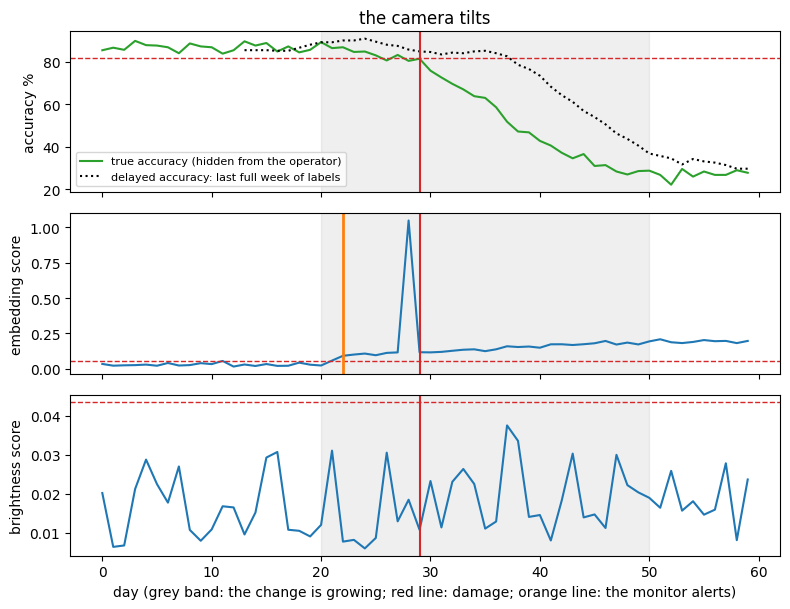

alerts: {'brightness': None, 'embedding': 22, 'confidence': 23, 'class_rate': 26} | damage starts day 29 | delayed-label alarm day 38

the numbers behind the picture, every third day:
 day  accuracy  delayed  embedding  confidence(mean)  brightness
   0    85.4%      -       0.034         86.8%         0.020
   3    89.8%      -       0.025         86.9%         0.021
   6    86.8%      -       0.040         86.6%         0.018
   9    87.2%      -       0.039         86.9%         0.008
  12    85.4%      -       0.015         86.5%         0.017
  15    88.8%    85.4%     0.033         85.6%         0.029
  18    84.4%    86.6%     0.043         84.8%         0.011
  21    86.4%    89.1%     0.057         85.7%         0.031
  24    84.8%    90.9%     0.107         82.0%         0.006
  27    83.2%    87.4%     0.115         80.9%         0.013
  30    75.8%    84.6%     0.115         75.4%         0.023
  33    67.0%    84.0%     0.134         70.2%         0.026
  36    58.6%    84

In [18]:
RESULT["camera tilts (to 40 degrees)"] = run_stream(SCENARIOS["camera tilts (to 40 degrees)"], seed=101)

def dashboard(res, title):
    d = np.arange(DAYS)
    fig, ax = plt.subplots(3, 1, figsize=(8, 6.2), sharex=True)
    ax[0].plot(d, 100 * res["acc"], color="tab:green", label="true accuracy (hidden from the operator)")
    ax[0].plot(d, 100 * res["delayed"], ":", color="k", label="delayed accuracy: last full week of labels")
    ax[0].axhline(100 * (VAL_ACC - 0.05), color="tab:red", ls="--", lw=1)
    ax[0].set_ylabel("accuracy %"); ax[0].legend(fontsize=8, loc="lower left"); ax[0].set_title(title)
    for a, k in [(ax[1], "embedding"), (ax[2], "brightness")]:
        a.plot(d, res["scores"][k], color="tab:blue"); a.axhline(THRESHOLD[k], color="tab:red", ls="--", lw=1)
        a.set_ylabel(k + " score")
        if res["alerts"][k] is not None: a.axvline(res["alerts"][k], color="tab:orange", lw=2)
    for a in ax:
        a.axvspan(START, FULL_DAY, color="grey", alpha=0.12)
        if res["damage"] is not None: a.axvline(res["damage"], color="tab:red", lw=1.5)
    ax[2].set_xlabel("day (grey band: the change is growing; red line: damage; orange line: the monitor alerts)")
    plt.tight_layout(); plt.show()

tilt = RESULT["camera tilts (to 40 degrees)"]
dashboard(tilt, "the camera tilts")
print("alerts:", tilt["alerts"], "| damage starts day", tilt["damage"], "| delayed-label alarm day", tilt["label_alert"])
print("\nthe numbers behind the picture, every third day:")
print(" day  accuracy  delayed  embedding  confidence(mean)  brightness")
for day in range(0, DAYS, 3):
    dl = "   -  " if np.isnan(tilt["delayed"][day]) else "%5.1f%%" % (100 * tilt["delayed"][day])
    print(f"{day:4d}   {100 * tilt['acc'][day]:5.1f}%   {dl}    {tilt['scores']['embedding'][day]:6.3f}        {100 * tilt['conf'][day]:5.1f}%        {tilt['scores']['brightness'][day]:6.3f}")

### Why we see this

The embedding and confidence monitors alert while the tilt is still small and the accuracy has barely moved.
The label-based alarm fires last, because it is looking at a week that is already a week old. The brightness
monitor never fires: turning an image does not change how bright it is. Had that been your only monitor, you
would have had a green dashboard and a model that was wrong most of the time.

---
## Step 19 - All eight scenarios

Now every scenario, with the same monitors and the same thresholds. Read the table row by row and ask of each
row: **did a label-free monitor alert before the damage, after it, or never?** And: **did an alert ring when
there was no damage?**

> **Predict before running:** fill in your own copy of the table with "early", "late", "never" or "false
> alarm" for each scenario. The last two rows are the ones to think hardest about.

In [19]:
for i, (name, make_day) in enumerate(SCENARIOS.items()):
    if name not in RESULT:
        RESULT[name] = run_stream(make_day, seed=100 + i)

fmt = lambda v: "  -" if v is None else "%3d" % v
print("accuracy: mean of days 0-19, then mean of days 50-59. Other columns: the DAY something happened ('-' = never).")
print(f"{'scenario':30s} {'acc before':>10s} {'acc after':>9s} {'damage':>7s} | {'bright':>6s} {'embed':>6s} {'conf':>5s} {'class':>6s} | {'labels':>6s}")
SUMMARY = {}
for name, res in RESULT.items():
    a0, a1 = 100 * res["acc"][:START].mean(), 100 * res["acc"][FULL_DAY:].mean()
    al = res["alerts"]
    first = min([v for v in al.values() if v is not None], default=None)
    SUMMARY[name] = dict(before=a0, after=a1, damage=res["damage"], first=first, labels=res["label_alert"], conf_before=100 * res["conf"][:START].mean(), conf_after=100 * res["conf"][FULL_DAY:].mean())
    print(f"{name:30s} {a0:9.1f}% {a1:8.1f}% {fmt(res['damage']):>7s} | {fmt(al['brightness']):>6s} {fmt(al['embedding']):>6s} {fmt(al['confidence']):>5s} {fmt(al['class_rate']):>6s} | {fmt(res['label_alert']):>6s}")

print("\nverdicts")
for name, s in SUMMARY.items():
    if s["damage"] is None and s["first"] is None: v = "quiet, and rightly so"
    elif s["damage"] is None: v = "ALERT WITHOUT DAMAGE: first alert day %d, accuracy went from %.1f%% to %.1f%%" % (s["first"], s["before"], s["after"])
    elif s["first"] is None: v = "MISSED: damage from day %d, no label-free monitor ever alerted; labels caught it on day %s" % (s["damage"], s["labels"])
    elif s["first"] < s["damage"]: v = "caught early: first alert day %d, %d days before the damage" % (s["first"], s["damage"] - s["first"])
    else: v = "caught late: first alert day %d, %d days after the damage began" % (s["first"], s["first"] - s["damage"])
    print(f"   {name:30s} {v}")
print("\nmean confidence, days 0-19 against days 50-59:")
for name, s in SUMMARY.items():
    print(f"   {name:30s} {s['conf_before']:5.1f}% -> {s['conf_after']:5.1f}%     (accuracy {s['before']:5.1f}% -> {s['after']:5.1f}%)")

accuracy: mean of days 0-19, then mean of days 50-59. Other columns: the DAY something happened ('-' = never).
scenario                       acc before acc after  damage | bright  embed  conf  class | labels
nothing changes                     86.7%     86.6%       - |      -      -     -      - |      -
camera tilts (to 40 degrees)        86.7%     27.2%      29 |      -     22    23     26 |     38
lens blurs (to sigma 2)             86.9%     65.7%      37 |      -     27    27     33 |     44
lighting dims (to 40%)              87.3%     84.4%       - |     24     24    27     47 |      -
more knitwear and shirts            87.0%     77.9%      35 |     28     27    27     25 |     47
a footwear promotion                86.6%     94.0%       - |     31     24    30     24 |      -
bags go on sale (to 30%)            86.0%     60.8%      26 |     47     37    30     47 |     38
the filing rule changes             86.8%     71.6%      21 |      -      -     -      - |     30

verdic

### Why we see this

Go through the rows.

- **Tilt and blur** are changes to the inputs that the model handles badly. The model's own internals feel
  them at once: the embedding moves and the confidence histogram changes shape, days before the accuracy
  has fallen by 5 points. This is the case label-free monitoring is good at.
- **Dimmer lighting** moves every monitor and costs little accuracy. The inputs really did change, and the
  model mostly coped. **Drift is not the same thing as damage.** An alert is a reason to look, not a verdict.
- **A different mix of classes** needs no unusual image at all. More of the hard classes pulls the average
  down, more of the easy ones pushes it up, and the monitors ring in both cases. They cannot tell you which
  way the accuracy went.
- **Bags** arrive as images the model was never taught, and it must still pick one of nine names. Every bag
  is a wrong answer, so accuracy falls point for point with their share of the traffic. A histogram of 500
  requests hardly moves when a few per cent of them are strange. Compare the day of the first alert with the
  day the damage began: the monitors were looking at the whole crowd, and the damage was in a small corner.
- **The filing rule changes** and not one pixel changes with it. The inputs are drawn from the same
  distribution as before, the model computes exactly what it computed before, and so every label-free monitor
  sits where it sat. Only labels can show this kind of change, and they show it late.

---
## Step 20 - Two closer looks: where the bags went, and the rule change

First, what does the model say about a class it has never seen? Then the dashboard for the changed rule.

> **Predict:** will the model's confidence on bags be near 1/9, the confidence of a blind guess?

1,000 bags, a class the model never saw. What it called them:
   Coat          23.9%
   Shirt         23.5%
   Dress         15.0%
   T-shirt/top   12.4%
mean confidence on bags: 55.4%   (on the reference window: 87.0%)
bags answered with confidence over 90%: 5.9%
bags that the Step 9 rule would send for review (under 60%): 62.7%


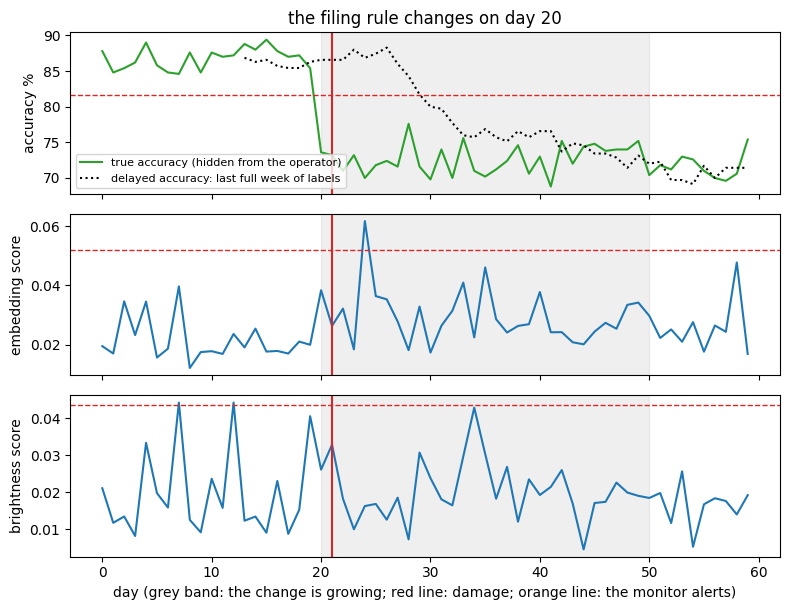

largest score reached after day 20, as a multiple of its threshold: {'brightness': 0.99, 'embedding': 1.19, 'confidence': 0.9, 'class_rate': 1.44}
days over threshold after day 20: {'brightness': 0, 'embedding': 1, 'confidence': 0, 'class_rate': 2}
true accuracy: 86.8% before, 72.4% after | damage day 21 | delayed-label alarm day 30

total running time of this notebook: 202 s


In [20]:
p_bag = model.predict(x_bag, batch_size=500, verbose=0)
bag_pred, bag_conf = p_bag.argmax(1), p_bag.max(1)
print("1,000 bags, a class the model never saw. What it called them:")
for c in np.argsort(-np.bincount(bag_pred, minlength=9))[:4]:
    print(f"   {NAMES[c]:12s} {100 * (bag_pred == c).mean():5.1f}%")
print("mean confidence on bags: %.1f%%   (on the reference window: %.1f%%)" % (100 * bag_conf.mean(), 100 * ref_conf.mean()))
print("bags answered with confidence over 90%%: %.1f%%" % (100 * (bag_conf > 0.9).mean()))
print("bags that the Step 9 rule would send for review (under %.0f%%): %.1f%%" % (100 * REVIEW_BELOW, 100 * (bag_conf < REVIEW_BELOW).mean()))

rule = RESULT["the filing rule changes"]
dashboard(rule, "the filing rule changes on day 20")
print("largest score reached after day 20, as a multiple of its threshold:",
      {k: round(float(rule["scores"][k][START:].max() / THRESHOLD[k]), 2) for k in MONITORS})
print("days over threshold after day 20:", {k: int((rule["scores"][k][START:] > THRESHOLD[k]).sum()) for k in MONITORS})
print("true accuracy: %.1f%% before, %.1f%% after | damage day %s | delayed-label alarm day %s" % (
      100 * rule["acc"][:START].mean(), 100 * rule["acc"][START:].mean(), rule["damage"], rule["label_alert"]))
print("\ntotal running time of this notebook: %.0f s" % (time.time() - t_start))

### Why we see this

A classifier has no output that means "none of these". Asked about a bag, it files it under whatever looks
most alike. This model is at least hesitant about bags: its confidence on them is well below normal, and the
review rule of Step 9 would hand most of them to a person. But a good share still go out as ordinary answers,
and a few with high confidence. Do not count on hesitation: Chapter 63 shows models that are confidently
wrong about inputs they have no business answering, and what to do about it.

The changed rule is the case to remember. The picture of the world the model sees is unchanged, so anything
computed from inputs and outputs is unchanged. The right answers moved, and the only instrument that reads
right answers is a labelled sample. **Label-free monitors are early and partly blind. Labels are late and see
everything.** A real service needs both.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | In Step 16 set `DAY_SIZE = 100` (and rerun from Step 15) | Do the thresholds rise or fall? Is the tilt caught earlier or later? | |
| 2 | In Step 15 put the thresholds at the 95th percentile, not the 99th | How many single-day crossings in the control? Does the two-day rule still protect you? | |
| 3 | In Step 16 change the alert rule to a single day over the threshold | How many false alerts across the eight scenarios? How many days earlier are the true ones? | |
| 4 | Set `LABEL_DELAY = 1` and `LABELS_PER_DAY = 200` | Which scenarios do labels now catch before the monitors? What would that cost a real team? | |
| 5 | In the tilt scenario stop at 15 degrees, not 40 | Does any monitor alert? Does damage ever start? | |
| 6 | Build the reference window from `x_fit[:9000]` (training images), not `x_val` | Which monitor's clean scores change most, and why? | |
| 7 | In Step 11 time `model(x, training=False)` at each batch size | Where does it catch up with the exported function? | |
| 8 | Raise `REVIEW_BELOW` to 0.9 in Step 9 | What share of answers goes to a person, and how accurate is the rest? | |

## Exercises

1. **A fifth monitor.** Add the share of answers with confidence under `REVIEW_BELOW` as a monitor, calibrate
   its threshold as in Step 15, and add its column to the table of Step 19. Does it beat the confidence
   histogram anywhere?
2. **A regression set.** Save 200 test images with the model's current answers into `WORK`. Write a function
   that loads any candidate model and reports how many of the 200 answers changed. Train a second model with
   another seed and run it. How many answers flip, although the accuracy is the same?
3. **Retrain on a trigger.** When the embedding monitor alerts in the tilt scenario, fine-tune the model for
   one epoch on tilted copies of `x_fit` and carry on with the stream. Draw the accuracy. Then do the wrong
   thing: fine-tune on the stream's images using the model's **own predictions** as labels, and compare.
4. **An invariance test.** A filed item should get the same label if the photo is shifted one pixel to the
   right. Measure on the test set how often the label changes. Is that a bug you would block a release for?
5. **Budget.** Your service must answer within 20 ms at the 95th percentile, and the network and queue take
   12 ms of it. Using your own Step 11 table, what is the largest batch the server may form?
6. **Slices.** Step 4 printed the accuracy for each class. Find the two classes that are most often confused
   with each other and write the one-line warning you would put in this model's documentation.

## Cheat sheet

| Job | How |
|---|---|
| Preprocessing inside the model | `layers.Rescaling(1/255)` after an `Input(dtype="uint8")` |
| Whole model, to resume or edit | `model.save("m.keras")`, `keras.models.load_model("m.keras")` |
| Weights only | `model.save_weights("m.weights.h5")` |
| Inference only | `model.export("folder")`, then `art = tf.saved_model.load("folder")`, `art.serve(x)` |
| On-device file | `model.export("m.tflite", format="litert")` |
| Prove a reload | same inputs, compare outputs: `np.abs(a - b).max()` |
| Latency | warm up, time many single requests, report median and p95, never the mean alone |
| Reference window | held-out data, never training data |
| Drift score | compare today's histogram with the reference; calibrate the threshold on clean batches of the same size |
| Label-free monitors | input statistics, embedding, confidence histogram, predicted-class rate |
| What they cannot see | a change in the right answer for the same input: only labels show it |